<div style="font-family:Times New Roman;font-size:14pt;color:black"><b>Лабораторна робота 2</b><br>Аналіз даних. Бібліотека Pandas<br>Виконав Шиндир Олексій<br>4 курс, 10 група</div>

<a href="https://colab.research.google.com/github/raysewww-lang/mashynne-navchannia/blob/main/%D0%A8%D0%B8%D0%BD%D0%B4%D0%B8%D1%80_%D0%BF%D1%80_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Відкрити в Colab"/></a>

In [1]:
# Підготовка бібліотек і даних. Дані автоматично завантажуються з GitHub; резервний спосіб — data.zip.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
np.random.seed(25)
plt.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','DejaVu Serif'],'font.size':14,'figure.figsize':(9,5)})
pd.set_option('display.max_columns',40)

def data_path(name):
    for folder in [Path('data'),Path('.'),Path('/content/data'),Path('/content')]:
        p=folder/name
        if p.exists():
            return p
    import zipfile, io
    from urllib.request import urlopen
    try:
        url='https://raw.githubusercontent.com/raysewww-lang/mashynne-navchannia/main/data.zip'
        with urlopen(url, timeout=60) as response:
            content=response.read()
        Path('data').mkdir(exist_ok=True)
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            for member in z.namelist():
                if not member.endswith('/'):
                    (Path('data')/Path(member).name).write_bytes(z.read(member))
        if (Path('data')/name).exists():
            return Path('data')/name
    except Exception as error:
        print('Автоматичне завантаження недоступне:',error)
    from google.colab import files
    import zipfile, io
    print('Завантажте data.zip або файл',name)
    uploaded=files.upload()
    Path('data').mkdir(exist_ok=True)
    for fname,content in uploaded.items():
        if fname.endswith('.zip'):
            with zipfile.ZipFile(io.BytesIO(content)) as z:
                for member in z.namelist():
                    if not member.endswith('/'):
                        (Path('data')/Path(member).name).write_bytes(z.read(member))
        else:
            (Path('data')/Path(fname).name).write_bytes(content)
    p=Path('data')/name
    if not p.exists():
        raise FileNotFoundError(name)
    return p

In [2]:
# Завдання 1. Зчитати таблицю ВВП з Вікіпедії. Пункти 1–5: перші рядки, розмір, вибір і назви стовпців, типи даних.
tables = pd.read_html(data_path('gdp_2024.html'))
raw = next(t for t in tables if isinstance(t.columns, pd.MultiIndex) and any('IMF' in str(x) for x in t.columns))
display(raw.head())
print('Початковий розмір:', raw.shape)
gdp = raw.iloc[:, [0, 1, 3, 5]].copy()
gdp.columns = ['Country', 'MVF_2024', 'WorldBank_2023', 'OON_2022']
print('Для аналізу потрібні 4 стовпці: країна і три оцінки ВВП.')
display(gdp.dtypes)
print('Джерело: https://en.wikipedia.org/w/index.php?oldid=1245669846')
print('Збережена версія від 14.09.2024. Роки окремих записів можуть відрізнятися; це оцінки трьох різних установ, а не єдиний часовий ряд.')
display(raw.iloc[:, [0,2,4,6]].head(15))

Country/Territory IMF[1][13]            World Bank[14]             \
  Country/Territory   Forecast       Year       Estimate       Year   
0             World  109529216       2024      105435540       2023   
1     United States   28781083       2024       27360935       2023   
2             China   18532633  [n 1]2024       17794782  [n 3]2023   
3           Germany    4591100       2024        4456081       2023   
4             Japan    4110452       2024        4212945       2023   

  United Nations[15]             
            Estimate       Year  
0          100834796       2022  
1           25744100       2022  
2           17963170  [n 1]2022  
3            4076923       2022  
4            4232173       2022

Початковий розмір: (231, 7)
Для аналізу потрібні 4 стовпці: країна і три оцінки ВВП.


Country           str
MVF_2024          str
WorldBank_2023    str
OON_2022          str
dtype: object

Джерело: https://en.wikipedia.org/w/index.php?oldid=1245669846
Збережена версія від 14.09.2024. Роки окремих записів можуть відрізнятися; це оцінки трьох різних установ, а не єдиний часовий ряд.


,Country/Territory,IMF[1][13],World Bank[14],United Nations[15]
,Country/Territory,Year,Year,Year
0,World,2024,2023,2022
1,United States,2024,2023,2022
2,China,[n 1]2024,[n 3]2023,[n 1]2022
3,Germany,2024,2023,2022
4,Japan,2024,2023,2022
5,India,2024,2023,2022
6,United Kingdom,2024,2023,2022
7,France,2024,2023,2022
8,Brazil,2024,2023,2022


In [3]:
# Завдання 1. Пункти 6–9: пропуски, числові типи, дублікати та описова статистика.
gdp['Country'] = gdp['Country'].str.replace(r'\[.*?\]', '', regex=True).str.strip()
gdp = gdp.dropna(subset=['Country'])
gdp = gdp[gdp['Country'] != 'World'].copy()
cols = ['MVF_2024', 'WorldBank_2023', 'OON_2022']
gdp[cols] = gdp[cols].replace('—', np.nan)
for col in cols:
    gdp[col] = pd.to_numeric(gdp[col].astype(str).str.replace(r'\[.*?\]', '', regex=True).str.replace(',', ''), errors='coerce')
print('Пропуски до заповнення:'); display(gdp.isna().sum())
gdp[cols] = gdp[cols].fillna(gdp[cols].mean())
print('Пропуски після заповнення:'); display(gdp.isna().sum())
print('Дублікати:', gdp.duplicated().sum())
gdp = gdp.drop_duplicates().reset_index(drop=True)
display(gdp.dtypes); display(gdp.describe())

Пропуски до заповнення:


Country            0
MVF_2024          15
WorldBank_2023     8
OON_2022           1
dtype: int64

Пропуски після заповнення:


Country           0
MVF_2024          0
WorldBank_2023    0
OON_2022          0
dtype: int64

Дублікати: 0


Country               str
MVF_2024          float64
WorldBank_2023    float64
OON_2022          float64
dtype: object

,MVF_2024,WorldBank_2023,OON_2022
count,2.090000e+02,2.090000e+02,2.090000e+02
mean,5.644339e+05,5.178115e+05,4.811087e+05
std,2.435307e+06,2.325859e+06,2.236743e+06
min,6.600000e+01,6.200000e+01,5.900000e+01
25%,1.446700e+04,1.043800e+04,8.772000e+03
50%,5.631000e+04,4.320500e+04,3.171700e+04
75%,4.099890e+05,3.355330e+05,2.371010e+05
max,2.878108e+07,2.736094e+07,2.574410e+07


In [4]:
# Завдання 1. Пункти 10–14: різниця оцінок, кореляція, середні, варіативність, найбільші та найменші значення.
gdp['Difference'] = gdp['MVF_2024'] - gdp['WorldBank_2023']
display(gdp[['Country','Difference']].sort_values('Difference',key=abs,ascending=False).head(10))
print('Найбільша абсолютна різниця:',gdp.loc[gdp['Difference'].abs().idxmax(),'Country'])
corr = gdp[cols].corr(); display(corr)
pairs = corr.where(np.triu(np.ones(corr.shape),1).astype(bool)).stack()
print('Найвища кореляція:',pairs.idxmax(),round(pairs.max(),4))
print('Середні значення:'); display(gdp[cols].mean())
gdp['Std'] = gdp[cols].std(axis=1)
print('Найбільша варіативність:',gdp.loc[gdp['Std'].idxmax(),['Country','Std']])
for col in cols:
    print(col,'максимум:',gdp.loc[gdp[col].idxmax(),['Country',col]].to_dict(),'мінімум:',gdp.loc[gdp[col].idxmin(),['Country',col]].to_dict())
print('Різниця середніх, МВФ мінус Світовий банк:',gdp[cols].mean().iloc[0]-gdp[cols].mean().iloc[1])

,Country,Difference
0,United States,1.420148e+06
1,China,7.378510e+05
195,Turks and Caicos Islands,5.630319e+05
192,Sint Maarten,5.628109e+05
177,Curaçao,5.613599e+05
175,Greenland,5.611979e+05
165,French Polynesia,5.586189e+05
163,Cayman Islands,5.578329e+05
159,Liechtenstein,5.570689e+05
160,Bermuda,5.566059e+05


Найбільша абсолютна різниця: United States


,MVF_2024,WorldBank_2023,OON_2022
MVF_2024,1.000000,0.998216,0.997244
WorldBank_2023,0.998216,1.000000,0.998610
OON_2022,0.997244,0.998610,1.000000


Найвища кореляція: ('WorldBank_2023', 'OON_2022') 0.9986
Середні значення:


MVF_2024          564433.932990
WorldBank_2023    517811.472637
OON_2022          481108.673077
dtype: float64

Найбільша варіативність: Country     United States
Std        1519552.648063
Name: 0, dtype: object
MVF_2024 максимум: {'Country': 'United States', 'MVF_2024': 28781083.0} мінімум: {'Country': 'Tuvalu', 'MVF_2024': 66.0}
WorldBank_2023 максимум: {'Country': 'United States', 'WorldBank_2023': 27360935.0} мінімум: {'Country': 'Tuvalu', 'WorldBank_2023': 62.0}
OON_2022 максимум: {'Country': 'United States', 'OON_2022': 25744100.0} мінімум: {'Country': 'Tuvalu', 'OON_2022': 59.0}
Різниця середніх, МВФ мінус Світовий банк: 46622.46035287471


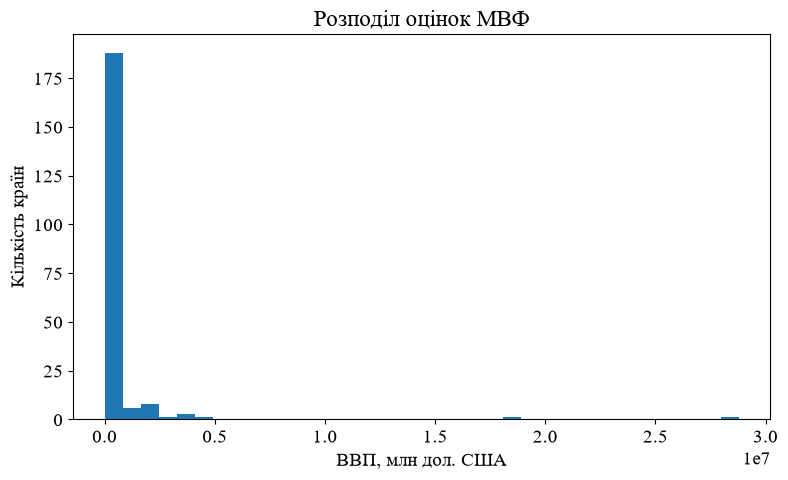

Розподіл має довгий правий хвіст. Найбільші економіки:


,Country,MVF_2024
0,United States,28781083.0
1,China,18532633.0
2,Germany,4591100.0
3,Japan,4110452.0
4,India,3937011.0


,MVF_2024,WorldBank_2023,OON_2022
Country,,,
United States,24.397635,25.282090,25.602846
China,15.710056,16.442760,17.864609
Germany,3.891861,4.117514,4.054554
Japan,3.484417,3.892851,4.208952
India,3.337392,3.280201,3.446526
...,...,...,...
Kiribati,0.000264,0.000258,0.000222
Palau,0.000261,0.000243,0.000224
Marshall Islands,0.000259,0.000262,0.000277


Найбільше збільшення частки:


Country
Turks and Caicos Islands    0.477337
Sint Maarten                0.476906
Zanzibar                    0.476121
Eritrea                     0.476099
Greenland                   0.475559
dtype: float64

Найбільше зменшення частки:


Country
China           -2.154553
United States   -1.205211
Japan           -0.724534
Russia          -0.484549
Nigeria         -0.258206
dtype: float64

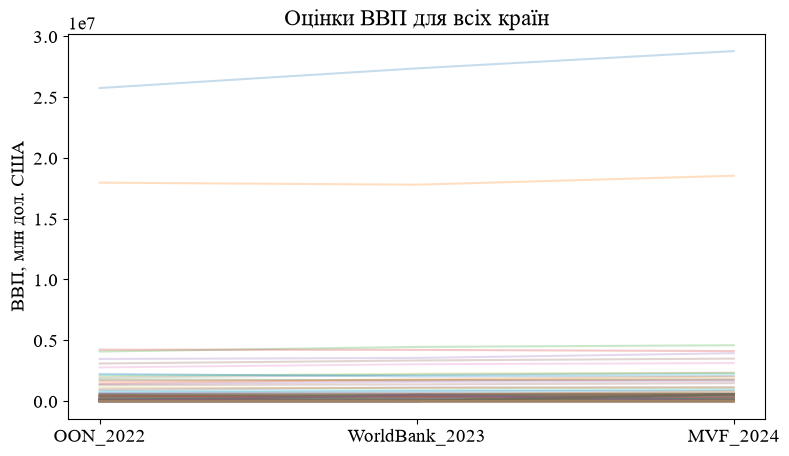

Послідовно більші оцінки: United States, Germany, India, United Kingdom, France, Brazil, Italy, Canada, Mexico, South Korea, Spain, Indonesia, Netherlands, Turkey, Switzerland, Poland, Taiwan, Belgium, Sweden, Ireland, Thailand, Austria, Singapore, Philippines, Vietnam, Iran, Bangladesh, Denmark, Hong Kong, Colombia, Romania, Finland, Portugal, Kazakhstan, Peru, Algeria, New Zealand, Greece, Hungary, Ethiopia, Ukraine, Morocco, Cuba, Slovakia, Dominican Republic, Ecuador, Guatemala, Bulgaria, Uzbekistan, Costa Rica, Luxembourg, Croatia, Panama, Ivory Coast, Uruguay, Serbia, Lithuania, Tanzania, DR Congo, Slovenia, Uganda, Tunisia, Macau, Jordan, Cameroon, Bolivia, Paraguay, Latvia, Cambodia, Nepal, Estonia, Honduras, Senegal, El Salvador, Zimbabwe, Cyprus, Iceland, Georgia, Bosnia and Herzegovina, Guinea, Albania, Armenia, Haiti, Mozambique, Malta, Mongolia, Burkina Faso, Mali, Benin, Guyana, Gabon, Jamaica, Nicaragua, Niger, Moldova, Madagascar, Mauritius, North Macedonia, North Korea

In [5]:
# Завдання 1. Пункти 15–17: гістограма, частки та графік оцінок усіх країн. Відповіді щодо розподілу і напрямку змін.
gdp['MVF_2024'].plot.hist(bins=35)
plt.xlabel('ВВП, млн дол. США'); plt.ylabel('Кількість країн'); plt.title('Розподіл оцінок МВФ'); plt.show()
print('Розподіл має довгий правий хвіст. Найбільші економіки:'); display(gdp.nlargest(5,'MVF_2024')[['Country','MVF_2024']])
shares = gdp[cols].div(gdp[cols].sum()) * 100
shares.index = gdp['Country']
display(shares)
delta = shares['MVF_2024'] - shares['OON_2022']
print('Найбільше збільшення частки:'); display(delta.nlargest(5))
print('Найбільше зменшення частки:'); display(delta.nsmallest(5))
order=['OON_2022','WorldBank_2023','MVF_2024']
values=gdp[order].to_numpy()
plt.plot(range(3),values.T,alpha=0.25)
plt.xticks(range(3),order);plt.ylabel('ВВП, млн дол. США');plt.title('Оцінки ВВП для всіх країн');plt.show()
growth=(values[:,1]>values[:,0]) & (values[:,2]>values[:,1])
decline=(values[:,1]<values[:,0]) & (values[:,2]<values[:,1])
print('Послідовно більші оцінки:',', '.join(gdp.loc[growth,'Country']))
print('Послідовно менші оцінки:',', '.join(gdp.loc[decline,'Country']))
print('Це порівняння джерел і різних років; воно не доводить стабільне економічне зростання чи спад. Частки також залежать від заповнення пропусків середнім.')

In [6]:
# Висновок. Завдання 1. Таблицю очищено, пропуски заповнено середнім згідно з умовою. Оцінки ВВП сильно корелюють; розподіл асиметричний. Порівняння різних установ не замінює аналіз одного часового ряду.

In [7]:
# Завдання 2. Титанік. Пункти 1–8: початковий аналіз, заповнення пропусків, дублікати, статистика, видалення Cabin.
titanic = pd.read_csv(data_path('titanic (5).csv'))
display(titanic.head()); print(titanic.shape); display(titanic.dtypes)
display(titanic.isna().sum())
num = titanic.select_dtypes(include='number').columns
titanic[num] = titanic[num].fillna(titanic[num].mean())
for col in titanic.select_dtypes(exclude='number').columns:
    titanic[col] = titanic[col].fillna(titanic[col].mode().iloc[0])
print('Категоріальні пропуски заповнено модою: арифметичне середнє для тексту не визначене.')
display(titanic.isna().sum()); print('Дублікати:',titanic.duplicated().sum())
titanic = titanic.drop_duplicates()
display(titanic.describe())
titanic = titanic.drop(columns='Cabin')

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


(891, 12)


PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Категоріальні пропуски заповнено модою: арифметичне середнє для тексту не визначене.


PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

Дублікати: 0


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.002015,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,29.699118,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
# Завдання 2. Пункти 9–13: обрати стовпці, перевірити стать, закодувати її, перевірити пропуски, перші та останні рядки.
titanic = titanic[['Survived','Pclass','Sex','Age','Fare']].copy()
print(titanic['Sex'].unique())
titanic['Sex'] = titanic['Sex'].map({'male':0,'female':1})
display(titanic.isna().sum()); display(titanic.head()); display(titanic.tail())

<StringArray>
['male', 'female']
Length: 2, dtype: str


Survived    0
Pclass      0
Sex         0
Age         0
Fare        0
dtype: int64

,Survived,Pclass,Sex,Age,Fare
0,0,3,0,22.0,7.2500
1,1,1,1,38.0,71.2833
2,1,3,1,26.0,7.9250
3,1,1,1,35.0,53.1000
4,0,3,0,35.0,8.0500


,Survived,Pclass,Sex,Age,Fare
886,0,2,0,27.000000,13.00
887,1,1,1,19.000000,30.00
888,0,3,1,29.699118,23.45
889,1,1,0,26.000000,30.00
890,0,3,0,32.000000,7.75


In [9]:
# Завдання 2. Пункти 14–19: виживання за статтю, класом, віком і тарифом; тарифи та вік за класами. Дати відповіді.
sex_rate=titanic.groupby('Sex')['Survived'].mean()*100
display(sex_rate.rename(index={0:'Чоловіки',1:'Жінки'}))
print('Різниця жінки мінус чоловіки, в.п.:',sex_rate.loc[1]-sex_rate.loc[0])
class_rate=titanic.groupby('Pclass')['Survived'].mean()*100
display(class_rate);print('Найвище виживання у класі:',class_rate.idxmax())
display(titanic.groupby('Survived')['Age'].mean())
print('Середні віки порівнюються описово; самі по собі вони не доводять причинний вплив віку.')
fare_groups=pd.qcut(titanic['Fare'],4,duplicates='drop')
fare_rate=titanic.groupby(fare_groups,observed=True)['Survived'].mean()*100
display(fare_rate);print('Найвище виживання в інтервалі тарифу:',str(fare_rate.idxmax()))
display(titanic.groupby('Pclass')['Fare'].mean())
print('Відношення середнього тарифу 1 класу до 3:',titanic.groupby('Pclass')['Fare'].mean().loc[1]/titanic.groupby('Pclass')['Fare'].mean().loc[3])
display(titanic.groupby('Pclass')['Age'].mean())
print('Найстарші в середньому:',titanic.groupby('Pclass')['Age'].mean().idxmax(),'клас')

Sex
Чоловіки    18.890815
Жінки       74.203822
Name: Survived, dtype: float64

Різниця жінки мінус чоловіки, в.п.: 55.31300709799203


Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

Найвище виживання у класі: 1


Survived
0    30.415100
1    28.549778
Name: Age, dtype: float64

Середні віки порівнюються описово; самі по собі вони не доводять причинний вплив віку.


... (2 outputs left out)

Pclass
1    84.154687
2    20.662183
3    13.675550
Name: Fare, dtype: float64

Відношення середнього тарифу 1 класу до 3: 6.153660136035067


Pclass
1    37.048118
2    29.866958
3    26.403259
Name: Age, dtype: float64

Найстарші в середньому: 1 клас


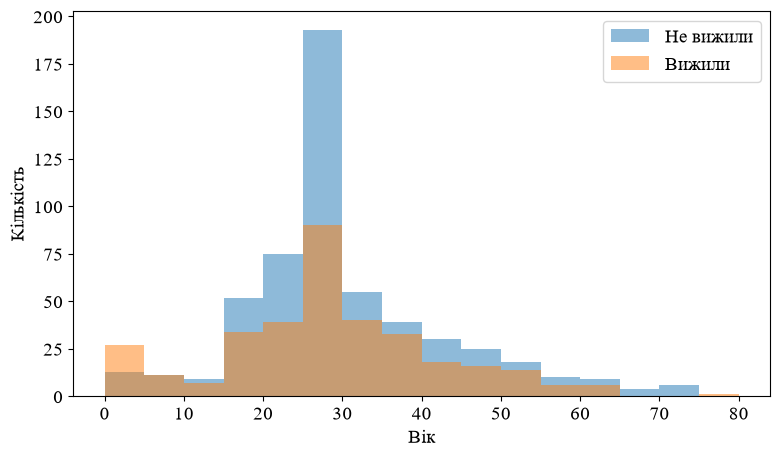

Age
(0, 12]      57.971014
(12, 18]     42.857143
(18, 35]     35.327103
(35, 60]     40.000000
(60, 100]    22.727273
Name: Survived, dtype: float64

Найвище виживання у віковій групі: (0, 12] . На гістограмі переважають дорослі, тому порівнюємо також частки.


Sex  Pclass
0    1         36.885246
     2         15.740741
     3         13.544669
1    1         96.808511
     2         92.105263
     3         50.000000
Name: Survived, dtype: float64

Найвище виживання, (стать, клас): (np.int64(1), np.int64(1)) де 1 — жінки


,Survived,Pclass,Age,Fare
Survived,1.000000,-0.338481,-0.069809,0.257307
Pclass,-0.338481,1.000000,-0.331339,-0.549500
Age,-0.069809,-0.331339,1.000000,0.091566
Fare,0.257307,-0.549500,0.091566,1.000000


Найсильніший зв’язок за модулем: Pclass


In [10]:
# Завдання 2. Пункти 20–22: гістограма віку за виживанням, комбінації статі й класу, кореляція з виживанням.
for outcome,label in [(0,'Не вижили'),(1,'Вижили')]:
    titanic.loc[titanic.Survived==outcome,'Age'].plot.hist(bins=np.arange(0,85,5),alpha=0.5,label=label)
plt.xlabel('Вік');plt.ylabel('Кількість');plt.legend();plt.show()
age_rate=titanic.groupby(pd.cut(titanic.Age,[0,12,18,35,60,100]),observed=True).Survived.mean()*100
display(age_rate)
print('Найвище виживання у віковій групі:',str(age_rate.idxmax()),'. На гістограмі переважають дорослі, тому порівнюємо також частки.')
combo=titanic.groupby(['Sex','Pclass']).Survived.mean()*100
display(combo);print('Найвище виживання, (стать, клас):',combo.idxmax(),'де 1 — жінки')
corr=titanic[['Survived','Pclass','Age','Fare']].corr();display(corr)
print('Найсильніший зв’язок за модулем:',corr.Survived.drop('Survived').abs().idxmax())

In [11]:
# Висновок. Завдання 2. Пропуски оброблено, стать закодовано. Виживання відрізняється між статями та класами; дорожчий тариф пов’язаний із класом. Це статистичні зв’язки, а не доказ причинності.